# 10. Grad-CAM implementation and testing

Celem niniejszego etapu jest implementacja i weryfikacja metody Grad-CAM (Gradient-weighted Class Activation Mapping) dla wybranego modelu klasyfikacji zmian skórnych. Metoda ta umożliwia wizualizację obszarów obrazu mających dodatni wpływ na wynik modelu dla wskazanej klasy.

## 1. Importy i konfiguracja środowiska

In [1]:
import sys
from pathlib import Path

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from PIL import Image

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.image_pipeline import create_dataset

from src.visualization import (
    colorize_heatmap,
    overlay_heatmap
)

from src.gradcam import (
    flatten_model,
    build_gradcam,
    generate_heatmap
)

I0000 00:00:1795874454.935482    7633 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795874455.040116    7633 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795874456.751442    7633 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
ALPHA = 0.2

DATASET_DIR = PROJECT_ROOT / "dataset"
MODEL_PATH = PROJECT_ROOT / "models" / "chosen.keras"

tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load(
    DATASET_DIR / "label_encoder.joblib"
)

class_names = label_encoder.classes_

## 2. Przygotowanie danych i wczytanie modelu

Do weryfikacji działania metody Grad-CAM wykorzystano obrazy pochodzące ze zbioru walidacyjnego. Dane przygotowano przy użyciu tego samego pipeline'u przetwarzania obrazów, który wykorzystano podczas ewaluacji modelu. Pozwala to zachować zgodność danych wejściowych z wcześniejszymi etapami projektu.

In [3]:
val_df = pd.read_csv(DATASET_DIR / "val_processed.csv")

val = create_dataset(
    val_df,
    training=False,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

print(f"Validation: {len(val_df)}")

images, labels = next(iter(val))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

W0000 00:00:1795874458.921401    7633 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1795874458.926526    7633 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795874459.115520    7633 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


Validation: 1602
Image batch: (32, 224, 224, 3)
Label batch: (32, 7)


In [4]:
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print(f"Model: {model.name}")
print(f"Input shape: {model.input_shape}")
print(f"Output shape: {model.output_shape}")
print(f"Parameters: {model.count_params():,}")

Model: CW10
Input shape: (None, 224, 224, 3)
Output shape: (None, 7)
Parameters: 4,058,538


## 3. Przygotowanie modelu do zastosowania Grad-CAM

In [5]:
for layer in model.layers:
    print(layer.name, type(layer).__name__)

input_layer InputLayer
functional Functional


In [6]:
backbone = model.get_layer("functional").get_layer("efficientnetb0")

for layer in backbone.layers[-15:]:
    print(layer.name, layer.output.shape)

block7a_expand_bn (None, 7, 7, 1152)
block7a_expand_activation (None, 7, 7, 1152)
block7a_dwconv (None, 7, 7, 1152)
block7a_bn (None, 7, 7, 1152)
block7a_activation (None, 7, 7, 1152)
block7a_se_squeeze (None, 1152)
block7a_se_reshape (None, 1, 1, 1152)
block7a_se_reduce (None, 1, 1, 48)
block7a_se_expand (None, 1, 1, 1152)
block7a_se_excite (None, 7, 7, 1152)
block7a_project_conv (None, 7, 7, 320)
block7a_project_bn (None, 7, 7, 320)
top_conv (None, 7, 7, 1280)
top_bn (None, 7, 7, 1280)
top_activation (None, 7, 7, 1280)


Ze względu na zagnieżdzoną strukturę wytrenowanego modelu, bezpośrednie utworzenie modelu pomocniczego wykorzystującego wewnętrzne warstwy sieci EfficientNet-B0 jest utrudnione. W celu uproszczenia dostępu do map cech zastosowano operację spłaszczenia architektury modelu, zachowując jego strukturę obliczeniową oraz wytrenowane wagi. 

In [7]:
flat_model = flatten_model(model)

target_layer = flat_model.get_layer("top_activation")

print(f"Target layer: {target_layer.name}")
print(f"Output shape: {target_layer.output.shape}")

gradcam = build_gradcam(model)

Target layer: top_activation
Output shape: (None, 7, 7, 1280)


Jako warstwę docelową wybrano top_activation, stanowiącą ostatnią przestrzenną reprezentację cech sieci EfficientNet-B0 przed operacją Global Average Pooling. Generuje ona 1280 map cech o rozdzielczości 7x7.

## 4. Weryfikacja poprawności implementacji

### 4.1. Zgodność modelu oryginalnego i spłaszczonego.

W celu sprawdzenia, czy operacja spłaszczenia architektury nie wpłynęła na działanie modelu, porównano wyniki predykcji modelu oryginalnego oraz spłaszczonego dla tej samej partii obrazów ze zbioru walidacyjnego. Różnica między nimi jest zerowa lub pomijalna.

In [8]:
original_predictions = model(
    images,
    training=False
).numpy()

flat_predictions = flat_model(
    images,
    training=False
).numpy()

max_difference = np.max(
    np.abs(original_predictions - flat_predictions)
)

print(f"Maximum absolute difference: {max_difference:.8e}")

np.testing.assert_allclose(
    original_predictions,
    flat_predictions,
    atol=1e-5,
    rtol=1e-5
)

I0000 00:00:1795874462.309839    7633 cuda_dnn.cc:461] Loaded cuDNN version 92400


Maximum absolute difference: 0.00000000e+00


## 4.2. Weryfikacja generowanych map aktywacji

In [9]:
samp_img = images[0:1]

for class_idx, class_name in enumerate(class_names):

    heatmap = np.asarray(
        generate_heatmap(
            gradcam,
            samp_img,
            class_idx
        )
    )

    assert heatmap.shape == (7, 7)
    assert np.isfinite(heatmap).all()
    assert heatmap.min() >= 0
    assert heatmap.max() <= 1 + 1e-6

    print(
        f"{class_name}: "
        f"shape={heatmap.shape}, "
        f"min={heatmap.min():.4f}, "
        f"max={heatmap.max():.4f}"
    )

print("Heatmap validation passed.")

akiec: shape=(7, 7), min=0.0000, max=1.0000
bcc: shape=(7, 7), min=0.0000, max=1.0000
bkl: shape=(7, 7), min=0.0000, max=1.0000
df: shape=(7, 7), min=0.0000, max=1.0000
mel: shape=(7, 7), min=0.0000, max=1.0000
nv: shape=(7, 7), min=0.0000, max=1.0000
vasc: shape=(7, 7), min=0.0000, max=1.0000
Heatmap validation passed.


## 5. Wizualizacja map aktywacji

In [10]:
def visualize_class_heatmaps(
    gradcam,
    sample,
    probabilities,
    true_idx,
    alpha=0.2
):
    predicted_idx = int(np.argmax(probabilities))
    image = Image.fromarray(sample[0].astype(np.uint8))

    fig, axes = plt.subplots(
        2, 4,
        figsize=(16, 9)
    )

    axes = axes.ravel()
    axes[0].imshow(image)
    axes[0].set_title("Original image")

    for idx, class_name in enumerate(class_names):

        heatmap = generate_heatmap(gradcam, sample, idx)
        heatmap_large = colorize_heatmap(np.asarray(heatmap), image.size)

        overlay = overlay_heatmap(
            image,
            heatmap_large,
            alpha=alpha
        )

        ax = axes[idx + 1]
        ax.imshow(overlay)

        ax.set_title(
            f"{class_name.upper()} "
            f"({probabilities[idx]:.2%})",
            fontweight=(
                "bold" if idx == predicted_idx
                else "normal"
            ),
            color=(
                "green" if idx == predicted_idx
                else "black"
            )
        )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"True class: {class_names[true_idx]} | "
        f"Predicted class: {class_names[predicted_idx]}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

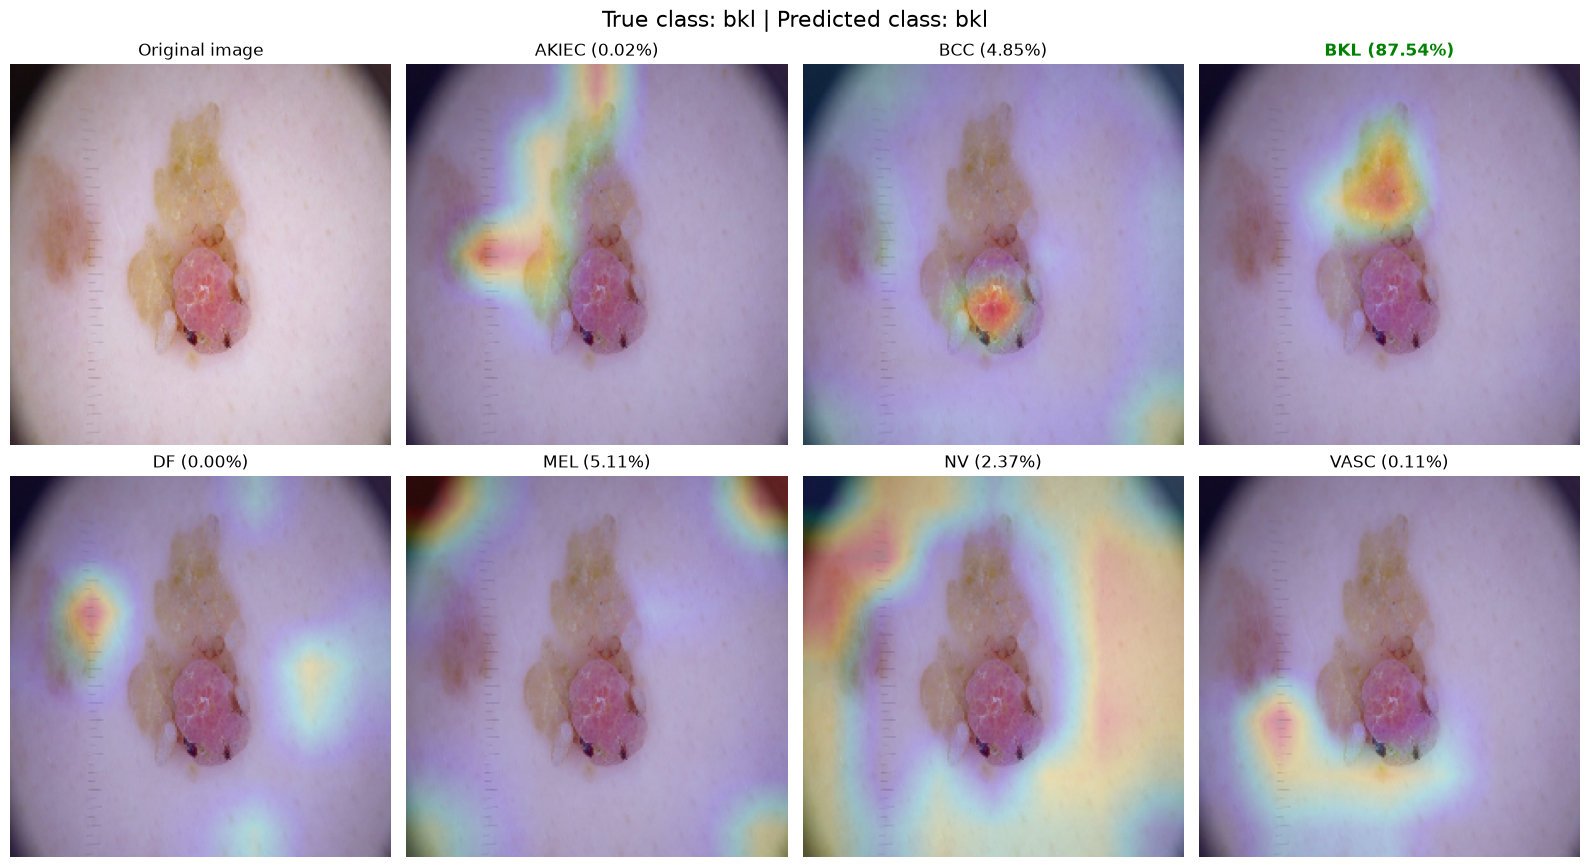

In [11]:
SAMPLE_IDX = 0

visualize_class_heatmaps(
    gradcam,
    np.asanyarray(images[SAMPLE_IDX:SAMPLE_IDX + 1]),
    original_predictions[SAMPLE_IDX],
    int(np.argmax(labels[SAMPLE_IDX])),
    alpha=ALPHA
)

Dla analizowanego przykładu model poprawnie przewidział klasę `bkl`, uzyskując wynik funkcji softmax wynoszący około 87,62%. Mapa aktywacji dla przewidzianej klasy koncentruje się przede wszystkim w górnej części zmiany skórnej.

W przypadku pozostałych klas zaobserwowano odmienne przestrzenne rozkłady istotności. Przykładowo dla klasy `bcc` obszar największej istotności znajduje się w dolnej części zmiany, natomiast dla klasy `mel` widoczne są aktywacje w narożnikach obrazu.

Uzyskane wizualizacje wskazują na zależność generowanych map od interpretowanej klasy. Jednocześnie obecność aktywacji poza obszarem zmiany skórnej może sugerować wykorzystywanie przez model informacji pochodzących z tła lub artefaktów obrazu.

## 6. Wnioski

- Zagnieżdżona architektura wytrenowanego modelu wymagała odpowiedniego przygotowania jego struktury w celu uzyskania dostępu do wewnętrznych map cech. W tym celu zastosowano operację spłaszczenia modelu.
- Jako warstwę docelową metody Grad-CAM wybrano `top_activation`, stanowiącą ostatnią przestrzenną reprezentację cech sieci EfficientNet-B0 przed operacją Global Average Pooling.
- Zaimplementowany mechanizm umożliwia generowanie map aktywacji dla dowolnej klasy, niezależnie od klasy przewidzianej przez model.
- Zaobserwowano różnice w przestrzennym rozkładzie istotności cech w zależności od interpretowanej klasy. W przypadku analizowanego przykładu mapa dla poprawnie przewidzianej klasy koncentrowała się przede wszystkim w obrębie zmiany skórnej.
- Dla niektórych klas zaobserwowano aktywacje również poza obszarem zmiany skórnej, co może sugerować wykorzystywanie przez model informacji pochodzących z tła lub artefaktów obrazu (Shortcut learning signs). Obserwacja ta wymaga dalszej weryfikacji.
- Rozdzielczość map aktywacji wynosząca 7 × 7 ogranicza precyzję przestrzenną uzyskiwanych wizualizacji. Zwiększenie rozdzielczości mapy poprzez interpolację nie zwiększa ilości informacji zawartej w mapie.
- Metoda Grad-CAM zwiększa interpretowalność wyników klasyfikacji, jednak nie stanowi potwierdzenia poprawności medycznej predykcji ani metody segmentacji zmian skórnych.
- Wydzielenie implementacji Grad-CAM oraz funkcji wizualizacyjnych do osobnych modułów umożliwia ich ponowne wykorzystanie podczas implementacji aplikacji webowej.